<a href="https://colab.research.google.com/github/imtanmoyd/ai_lab/blob/main/q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BFS Traversal Order: ['A', 'B', 'C', 'D', 'E', 'F']
DFS Traversal Order: ['A', 'B', 'D', 'E', 'C', 'F']


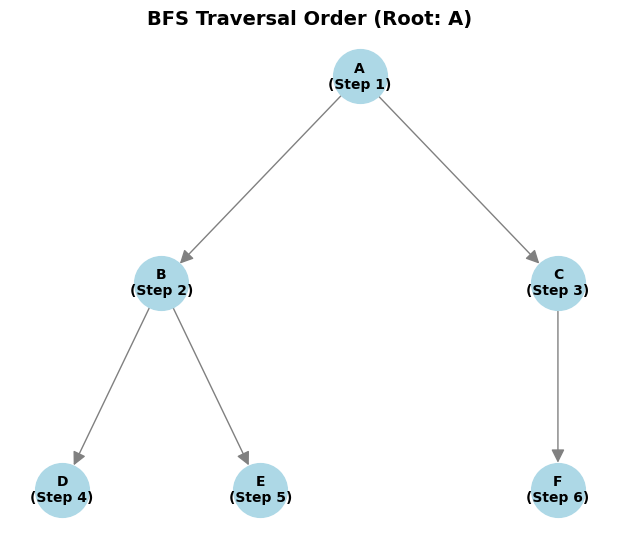

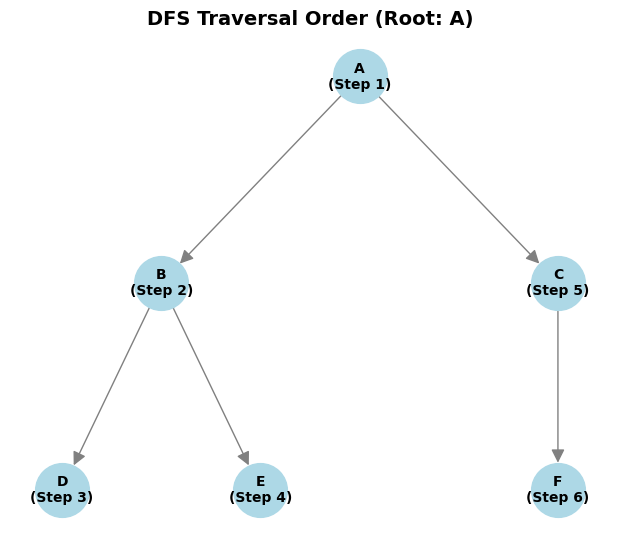

In [1]:
import collections
import matplotlib.pyplot as plt
import networkx as nx

# 1. Store the graph using an adjacency list (a Python dictionary)
# Defining a simple 6-node tree with A as the root
# Structure:
#      A
#     / \
#    B   C
#   / \   \
#  D   E   F
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': []
}

# 2. Perform BFS traversal starting from node A
def bfs(graph, start):
    visited = []
    queue = collections.deque([start])

    while queue:
        node = queue.popleft()
        if node not in visited:
            visited.append(node)
            queue.extend(graph[node])
    return visited

# 3. Perform DFS traversal starting from node A
def dfs(graph, start):
    visited = []
    stack = [start]

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.append(node)
            # Push neighbors in reverse order so we visit left-to-right
            stack.extend(reversed(graph[node]))
    return visited

# Run traversals
bfs_order = bfs(graph, 'A')
dfs_order = dfs(graph, 'A')

print(f"BFS Traversal Order: {bfs_order}")
print(f"DFS Traversal Order: {dfs_order}")

# 4. Draw tree diagrams showing traversal orders
def draw_traversal_tree(graph, traversal_order, title):
    G = nx.DiGraph()
    for parent, children in graph.items():
        for child in children:
            G.add_edge(parent, child)

    # Position layout representing a tree hierarchy
    pos = {
        'A': (0, 2),
        'B': (-1, 1), 'C': (1, 1),
        'D': (-1.5, 0), 'E': (-0.5, 0), 'F': (1, 0)
    }

    # Generate labels indicating the step number at which each node was visited
    labels = {node: f"{node}\n(Step {traversal_order.index(node) + 1})" for node in G.nodes()}

    plt.figure(figsize=(6, 5))
    nx.draw(G, pos, with_labels=True, labels=labels, node_size=1500,
            node_color='lightblue', font_size=10, font_weight='bold',
            arrows=True, arrowsize=20, edge_color='gray')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.show()

# Draw BFS Tree
draw_traversal_tree(graph, bfs_order, "BFS Traversal Order (Root: A)")

# Draw DFS Tree
draw_traversal_tree(graph, dfs_order, "DFS Traversal Order (Root: A)")